## ÍNDICE DEL PROYECTO

* [Introducción](#INTRODUCCIÓN)
* [1. Análisis y Exploración del Dataset](#1.-Análisis-y-Exploración-del-Dataset)
   * [1.1 Carga de Matrices y Limpieza de Estructuras](#1.1.-Carga-de-Matrices-y-Limpieza-de-Estructuras)
   * [1.2 Verificación de Datos Faltantes e Integridad Numérica](#1.2.-Verificación-de-Datos-Faltantes-e-Integridad-Numérica)
   * [1.3 Mapeo de Entidades (CEDIS y Sucursales)](#1.3.-Mapeo-de-Entidades-(CEDIS-y-Sucursales))
   * [1.4 Resumen Estadístico de Distancias y Costos](#1.4.-Resumen-Estadístico-de-Distancias-y-Costos)
* [2. Modelado del Problema Combinatorio (VRP Multi-Depósito)](#2-modelado-del-problema-combinatorio-vrp)
   * [2.1 Formulación Matemática del Problema](#2.1.-Formulación-Matemática-del-Problema)
   * [2.2 Definición de la Función Objetivo de Costo y Distancia](#2.2.-Definición-de-la-Función-Objetivo-de-Costo-y-Distancia)
   * [2.3 Solucion inicial](#23-solucion-inicial)
   * [2.4 Evaluación de la Ruta de Línea Base (Baseline)](#2.4.-Evaluación-de-la-Ruta-de-Línea-Base-(Baseline))
* [3. Desarrollo e Implementación del Algoritmo Heurístico](#3-desarrollo-e-implementación-del-algoritmo-heurístico)
   * [3.1 Justificación Teórica de Recocido Simulado](#3.1.-Justificación-Teórica-de-Recocido-Simulado)
   * [3.2 Operador de Vecindad (Swap)](#3.2.-Operador-de-Vecindad-(Swap-/-Intercambio-2-Opt))
   * [3.3 Función de Validación de Rutas y Restricciones](#3.3.-Función-de-Validación-de-Rutas-y-Restricciones)
   * [3.4 Estructura del Algoritmo de Recocido Simulado (Criterio de Metropolis)](#3.4.-Estructura-del-Algoritmo-de-Recocido-Simulado-(Criterio-de-Metropolis))
* [4. Ejecución de Simulaciones y Registro de Métricas](#4-ejecución-de-simulaciones-y-registro-de-métricas)
   * [4.1 Configuración de Parámetros de Enfriamiento](#4.1.-Configuración-de-Parámetros-de-Enfriamiento)
   * [4.2 Ejecución de la Simulación y Tracking de Costos](#4.2.-Ejecución-de-la-Simulación-y-Tracking-de-Costos)
   * [4.3 Registro de la Mejor Ruta y Comparativa Directa](#4.3.-Registro-de-la-Mejor-Ruta-y-Comparativa-Directa)
* [5. Evaluación de Rendimiento y Comparativa](#5-evaluación-de-rendimiento-y-comparativa)
   * [5.1 Análisis de Convergencia Visual (Curva de Enfriamiento)](#5.1.-Análisis-de-Convergencia-Visual-(Curva-de-Enfriamiento))
   * [5.2 Cálculo de Ahorro Porcentual en Combustible y Distancia](#5.2.-Cálculo-de-Ahorro-Porcentual-en-Combustible-y-Distancia)
* [6. Representacion gráfica de Solucion Optimizada](#6.-Representacion-gráfica-de-Solucion-Optimizada)
* [Conclusiones y Análisis de Resultados](#Conclusiones-y-Análisis-de-Resultados)

## Introducción

La distribución logística de insumos de abarrotes en Culiacán, Sinaloa, presenta retos operativos debido a la dispersión geográfica de las sucursales, patrones de tráfico urbano y variaciones en los costos de consumo de combustible. Probar todas las combinaciones de rutas de forma exhaustiva resulta inviable ya que el Problema de Enrutamiento de Vehículos Multi-Depósito (MDVRP) es de complejidad $NP$-hard.

En esta libreta se documenta el diseño, modelado e implementación computacional de una solución basada en la metaheurística de **Recocido Simulado (Simulated Annealing)** en Python. A diferencia del modelo simple de depósito único, se plantea una estrategia de **Construcción Intercalada Uniforme** que asigna equitativamente las 90 sucursales entre los 10 Centros de Distribución (CEDIS) disponibles (9 tiendas por CEDIS). El objetivo es minimizar la distancia recorrida y los costos asociados de combustible en los 10 circuitos de reparto de Culiacán, garantizando eficiencia logística, comparabilidad frente a la solución inicial sin optimizar y visualización geoespacial interactiva.

## 1.- Análisis y Exploración del Dataset

En este primer paso importamos las librerías necesarias y realizamos la lectura de los tres archivos base del proyecto:
- `datos_distribucion_tiendas.xlsx`: Información descriptiva de los 100 nodos (tipo, coordenadas, capacidades).
- `matriz_distancias.xlsx`: Matriz de $100 \times 100$ con las distancias inter-nodo en kilómetros.
- `matriz_costos_combustible.xlsx`: Matriz de $100 \times 100$ con los costos de consumo de combustible en MXN.

### 1.1.- Carga de Matrices y Limpieza de Estructuras

**Funciones y atributos utilizados:**
1. **`pd.read_excel()`**: Carga el contenido de los archivos de Excel en un DataFrame de Pandas.
2. **`.to_numpy()`**: Convierte las matrices bidimensionales de Pandas en arreglos matriciales de NumPy para optimizar sustancialmente la velocidad de cálculo aritmético durante las iteraciones del algoritmo.
3. **`.shape`**: Retorna una tupla con las dimensiones (filas, columnas) de los conjuntos de datos.
4. **`.value_counts()`**: Contabiliza la cantidad de registros por tipo de inmueble (Centro de Distribución vs. Tienda).

In [71]:
import numpy as np
import pandas as pd

# Lectura de los archivos Excel suministrados
df_tiendas = pd.read_excel('./Datasets/datos_distribucion_tiendas.xlsx')
df_distancias = pd.read_excel('./Datasets/matriz_distancias.xlsx')
df_costos = pd.read_excel('./Datasets/matriz_costos_combustible.xlsx')

# Conversión a matrices NumPy para facilitar el procesamiento
matriz_dist = df_distancias.to_numpy()
matriz_costo = df_costos.to_numpy()

# Validación de estructuras de datos y verificación de dimensiones
print('=== VERIFICACIÓN DE ESTRUCTURAS DE DATOS===')
print(f'Dimensiones Matriz Distancias: {matriz_dist.shape} (Esperado: 100x100)')
print(f'Dimensiones Matriz Costos:{matriz_costo.shape} (Esperado: 100x100)')
print('\nDesglose de Entidades en el Dataset:')
print(df_tiendas['Tipo'].value_counts())

# Vista previa de las matrices (Muestra de 5x5 para no saturar la pantalla)
print('\n=== VISTA PREVIA: MATRIZ DE DISTANCIAS (km) ===')
display(df_distancias.iloc[:5, :5])

print('\n=== VISTA PREVIA: MATRIZ DE COSTOS (MXN) ===')
display(df_costos.iloc[:5, :5])

=== VERIFICACIÓN DE ESTRUCTURAS DE DATOS===
Dimensiones Matriz Distancias: (100, 100) (Esperado: 100x100)
Dimensiones Matriz Costos:(100, 100) (Esperado: 100x100)

Desglose de Entidades en el Dataset:
Tipo
Tienda                    90
Centro de Distribución    10
Name: count, dtype: int64

=== VISTA PREVIA: MATRIZ DE DISTANCIAS (km) ===


,Nodo_1,Nodo_2,Nodo_3,Nodo_4,Nodo_5
0,0.000000,22.027423,16.103521,15.988868,12.228125
1,22.027423,0.000000,13.763643,11.832109,19.517618
2,16.103521,13.763643,0.000000,18.401809,6.880980
3,15.988868,11.832109,18.401809,0.000000,20.688967
4,12.228125,19.517618,6.880980,20.688967,0.000000



=== VISTA PREVIA: MATRIZ DE COSTOS (MXN) ===


,Nodo_1,Nodo_2,Nodo_3,Nodo_4,Nodo_5
0,0.000000,3.304114,2.415528,2.398330,1.834219
1,3.304114,0.000000,2.064546,1.774816,2.927643
2,2.415528,2.064546,0.000000,2.760271,1.032147
3,2.398330,1.774816,2.760271,0.000000,3.103345
4,1.834219,2.927643,1.032147,3.103345,0.000000


## 1.2 Verificación de Datos Faltantes e Integridad Numérica

Antes de realizar cualquier cálculo, debemos comprobar que las matrices estén completas y no contengan valores nulos o vacíos (`NaN`).

**Funciones utilizadas:**
1. **`.isnull()`**: Identifica si existen celdas sin datos en los DataFrames.
2. **`.sum().sum()`**: Suma el total de celdas nulas en toda la matriz.

In [72]:
# Contar valores nulos en columnas clave de identificación y ubicación
cols_clave = ['Tipo', 'Nombre', 'Latitud_WGS84', 'Longitud_WGS84']

# Nulos en CEDIS y Tiendas evaluando sus datos de ubicación
nulos_cedis = (
    df_tiendas[df_tiendas['Tipo'] == 'Centro de Distribución'][cols_clave]
    .isnull()
    .sum()
    .sum()
)
nulos_tiendas = (
    df_tiendas[df_tiendas['Tipo'] == 'Tienda'][cols_clave].isnull().sum().sum()
)

# Nulos en matrices de distancia y costo
nulos_dist = df_distancias.isnull().sum().sum()
nulos_costos = df_costos.isnull().sum().sum()

print('=== REVISIÓN DE DATOS FALTANTES ===')
print(f'Valores nulos en CEDIS:        {nulos_cedis}')
print(f'Valores nulos en Tiendas:      {nulos_tiendas}')
print(f'Valores nulos en Distancias:   {nulos_dist}')
print(f'Valores nulos en Costos:       {nulos_costos}')

if nulos_cedis + nulos_tiendas + nulos_dist + nulos_costos == 0:
  print('\nLas matrices están completas y sin datos faltantes.')

=== REVISIÓN DE DATOS FALTANTES ===
Valores nulos en CEDIS:        0
Valores nulos en Tiendas:      0
Valores nulos en Distancias:   0
Valores nulos en Costos:       0

Las matrices están completas y sin datos faltantes.


## 1.3 Mapeo de Entidades (CEDIS y Sucursales)

En este subpaso organizamos las 100 entidades del dataset en sus dos categorías principales: los 10 Centros de Distribución (**CEDIS**, índices 0 al 9) y las 90 sucursales destino (**Tiendas**, índices 10 al 99).

A diferencia de un modelo de punto único de salida, en esta arquitectura **utilizaremos los 10 CEDIS disponibles**, repartiendo equitativamente las 90 sucursales entre ellos (9 tiendas por CEDIS). Para mantener la libreta clara, visualizamos una muestra representativa de cada grupo mostrando la totalidad de sus columnas.

### Detalles de la Implementación:
1. **Filtro por Tipo de Entidad:** Separamos el DataFrame en `cedis_df` (10 almacenes) y `tiendas_df` (90 sucursales) usando el campo `Tipo`.
2. **Definición de Entidades:** Identificamos la lista completa de CEDIS (`cedis_indices = [0..9]`) y la lista de tiendas a distribuir (`sucursales_indices = [10..99]`).
3. **Visualización Controlada:** Desplegamos las tablas completas de los 10 CEDIS y una muestra de las primeras 10 tiendas mediante `.head(10)`.

**Funciones utilizadas:**
- **`df['Tipo'] == '...'`**: Filtra el DataFrame según el tipo de instalación.
- **`.head(10)`**: Devuelve las primeras 10 filas del DataFrame.
- **`display()`**: Renderiza la tabla en formato estilizado dentro de Jupyter.
- **`list(range())`**: Genera la secuencia numérica de índices de nodos.

In [73]:
# # Visualizar la tabla completa de df_tiendas como DataFrame
# with pd.option_context('display.max_rows', None, 'display.max_columns', None):
#   display(df_tiendas)

# 1. Separar CEDIS y Tiendas
cedis_df = df_tiendas[df_tiendas['Tipo'] == 'Centro de Distribución']
tiendas_df = df_tiendas[df_tiendas['Tipo'] == 'Tienda']

# 2. Extracción de listas globales de índices para CEDIS (0-9) y Tiendas (10-99)
cedis_indices = list(range(len(cedis_df)))
sucursales_indices = list(range(len(cedis_df), len(df_tiendas)))

# 3. Mostrar los 10 Centros de Distribución con todas sus columnas
print('=== CENTROS DE DISTRIBUCIÓN DISPONIBLES (10 CEDIS) ===')
display(cedis_df)

# 4. Mostrar Muestra de 10 Sucursales a Entregar
print('\n=== MUESTRA DE SUCURSALES A ENTREGAR (10 TIENDAS) ===')
display(tiendas_df.head(10))

print('\n=== RESUMEN DEL MAPEO MULTI-DEPÓSITO ===')
print(f'Total de CEDIS activos en la red:   {len(cedis_indices)}')
print(f'Total de Tiendas a entregar:        {len(sucursales_indices)}')
print(f'Promedio de Tiendas por CEDIS:      {len(sucursales_indices) // len(cedis_indices)}')

=== CENTROS DE DISTRIBUCIÓN DISPONIBLES (10 CEDIS) ===


,Tipo,Nombre,Latitud_WGS84,Longitud_WGS84,Capacidad_Venta,Capacidad_Almacenamiento,Nivel_Tienda
0,Centro de Distribución,Centro de Distribución 1,24.774908,-107.309857,13648,11639,NaN
1,Centro de Distribución,Centro de Distribución 2,24.846399,-107.380268,19012,26049,NaN
2,Centro de Distribución,Centro de Distribución 3,24.731204,-107.468801,17314,19144,NaN
3,Centro de Distribución,Centro de Distribución 4,24.711617,-107.326765,13358,45741,NaN
4,Centro de Distribución,Centro de Distribución 5,24.820223,-107.358385,12848,48698,NaN
5,Centro de Distribución,Centro de Distribución 6,24.704117,-107.306018,23825,12082,NaN
6,Centro de Distribución,Centro de Distribución 7,24.866489,-107.457532,10976,16140,NaN
7,Centro de Distribución,Centro de Distribución 8,24.736365,-107.463319,17164,25247,NaN
8,Centro de Distribución,Centro de Distribución 9,24.760848,-107.395049,26559,49453,NaN
9,Centro de Distribución,Centro de Distribución 10,24.786389,-107.441754,10869,46781,NaN



=== MUESTRA DE SUCURSALES A ENTREGAR (10 TIENDAS) ===


,Tipo,Nombre,Latitud_WGS84,Longitud_WGS84,Capacidad_Venta,Capacidad_Almacenamiento,Nivel_Tienda
10,Tienda,Tienda 1,24.822371,-107.472101,8257,14731,C
11,Tienda,Tienda 2,24.758429,-107.426728,16490,11928,B
12,Tienda,Tienda 3,24.791214,-107.342965,8611,10359,C
13,Tienda,Tienda 4,24.739935,-107.397153,9557,3106,A
14,Tienda,Tienda 5,24.818483,-107.490710,16438,9924,B
15,Tienda,Tienda 6,24.821509,-107.465895,9552,5547,A
16,Tienda,Tienda 7,24.713010,-107.310223,17509,8514,A
17,Tienda,Tienda 8,24.893126,-107.338321,6519,9224,A
18,Tienda,Tienda 9,24.760923,-107.480466,10881,8635,C
19,Tienda,Tienda 10,24.836847,-107.411970,9333,3711,C



=== RESUMEN DEL MAPEO MULTI-DEPÓSITO ===
Total de CEDIS activos en la red:   10
Total de Tiendas a entregar:        90
Promedio de Tiendas por CEDIS:      9


### 1.4 Resumen Estadístico de Distancias y Costos

Analizamos los valores mínimos, máximos y promedios de distancia y costo entre todos los puntos para entender la escala geográfica y económica del problema.

**Funciones utilizadas:**
1. **`np.min()`**: Encuentra el valor mínimo (ignorando la diagonal principal de distancia 0).
2. **`np.max()`**: Encuentra la distancia o costo más elevado entre dos nodos.
3. **`np.mean()`**: Calcula el valor promedio.

In [74]:
# Creación de copia de las matrices ignorando los ceros de la diagonal principal (distancia a uno mismo)
dist_sin_ceros = matriz_dist[matriz_dist > 0]
costos_sin_ceros = matriz_costo[matriz_costo > 0]

print('=== RESUMEN ESTADÍSTICO DE DISTANCIAS Y COSTOS ===')
print(f'Distancia Mínima entre nodos: {np.min(dist_sin_ceros):.2f} km')
print(f'Distancia Máxima entre nodos: {np.max(dist_sin_ceros):.2f} km')
print(f'Distancia Promedio:           {np.mean(dist_sin_ceros):.2f} km')
print('-----------------------------------------')
print(f'Costo Mínimo por tramo:       ${np.min(costos_sin_ceros):.2f} MXN')
print(f'Costo Máximo por tramo:       ${np.max(costos_sin_ceros):.2f} MXN')
print(f'Costo Promedio por tramo:     ${np.mean(costos_sin_ceros):.2f} MXN')

=== RESUMEN ESTADÍSTICO DE DISTANCIAS Y COSTOS ===
Distancia Mínima entre nodos: 0.12 km
Distancia Máxima entre nodos: 27.35 km
Distancia Promedio:           11.38 km
-----------------------------------------
Costo Mínimo por tramo:       $0.02 MXN
Costo Máximo por tramo:       $4.10 MXN
Costo Promedio por tramo:     $1.71 MXN


## 2. Modelado del Problema Combinatorio (VRP Multi-Depósito)

En esta sección traducimos la logística de distribución de insumos en Culiacán a un modelo matemático de **Problema de Enrutamiento de Vehículos Multi-Depósito**. 

A diferencia del modelo simple de vehículo único con un solo depósito, se formula una estructura de **10 circuitos cerrados independientes** en los cuales cada Centro de Distribución (CEDIS) actúa como punto de origen y retorno de un vehículo que abastece a un grupo equitativo de $9$ sucursales, formando una red global de $100$ nodos.

### 2.1 Formulación Matemática del Problema

Representamos la red de distribución logística en Culiacán mediante un grafo completo $G = (V, E)$:
- $V = \{0, 1, \dots, 9\} \cup \{10, 11, \dots, 99\}$ es el conjunto de $100$ nodos. Los índices $0 \dots 9$ representan los 10 Centros de Distribución (CEDIS) y $10 \dots 99$ representan las 90 sucursales de restaurantes.
- $E = \{(i, j) : i, j \in V, i \neq j\}$ es el conjunto de aristas que conectan cada par de ubicaciones de la red.
- $C_{ij}$ representa el costo de consumo de combustible en MXN o la distancia en kilómetros para trasladarse del nodo $i$ al nodo $j$.

### 2.2 Definición de la Función Objetivo de Costo y Distancia

La solución global se representa como un vector intercalado de $100$ elementos agrupados en $10$ bloques continuos $B_1, B_2, \dots, B_{10}$. Cada bloque $B_m = (c_m, t_{m,1}, t_{m,2}, \dots, t_{m,9})$ inicia con un CEDIS de origen $c_m$ seguido de sus $9$ tiendas asignadas.

El costo total se calcula sumando el costo de los $10$ circuitos independientes de salida, entrega inter-tiendas y retorno al CEDIS:

$$\text{Costo Total} = \sum_{m=1}^{10} (\text{Costo}_{\text{salida}} + \text{Costo}_{\text{intermedios}} + \text{Costo}_{\text{retorno}})$$

**Funciones y operadores utilizados:**
1. `def`: Define la función de evaluación `calcular_costo_ruta`.
2. `for i in range(0, len, 10)`: Recorre los 10 bloques en saltos de 10 posiciones.
3. `+=`: Acumula el costo o distancia de los 10 circuitos en la variable total.

In [75]:
def calcular_costo_ruta(vector_solucion, matriz_evaluacion):
  """Calcula el costo o distancia total acumulada de las 10 rutas independientes (1 CEDIS + 9 Tiendas cada una)."""
  costo_total = 0.0
  tamano_grupo = 10  # 1 CEDIS + 9 tiendas

  # Recorrer los 10 bloques de la solución
  for i in range(0, len(vector_solucion), tamano_grupo):
    cedi_origen = vector_solucion[i]
    tiendas_bloque = vector_solucion[i + 1 : i + tamano_grupo]

    # 1. Tramo: Del CEDIS del bloque a la primera tienda del bloque
    costo_total += matriz_evaluacion[cedi_origen][tiendas_bloque[0]]

    # 2. Tramos entre tiendas del mismo bloque
    for k in range(len(tiendas_bloque) - 1):
      costo_total += matriz_evaluacion[tiendas_bloque[k]][
          tiendas_bloque[k + 1]
      ]

    # 3. Tramo de regreso: De la última tienda del bloque al CEDIS del bloque
    costo_total += matriz_evaluacion[tiendas_bloque[-1]][cedi_origen]

  return costo_total

### 2.3 Solucion inicial
Para implementar el recocido simulado se debe tener una solucion inicial, para esto se decidio utilizar la **Construccion intercalada uniforme**. A diferencia de una solución totalmente aleatoria (donde los CEDIS y las tiendas podrían quedar revueltos en cualquier orden sin control), esta estrategia construye la solucion inicial de forma estructurada mediante dos principios básicos:Intercalado Secuencial (CEDIS como delimitadores) y reparto equitativo de carga.

### Intercalado secuencial
Como el vector de la solución utiliza un formato global donde los números del 0 al 9 son los 10 CEDIS y del 10 al 99 son las 90 tiendas, la solución inicial coloca un CEDIS seguido de un bloque de tiendas, y luego el siguiente CEDIS: 

Vector inicial = {C1, Ta,Tb,...,Ti,C2,Tj,Tk,...,Tm,....,C10,Tx,...,Tz}  

Donde C es un CEDIS y T es una tienda.

### Reparto equitativo de carga
Como hay 90 tiendas y 10 CEDIS, calcula la división $\frac{90}{10} = 9$ tiendas por cada centro ademas que  mezcla aleatoriamente los IDs de los CEDIS y los IDs de las tiendas por separado antes de formar las parejas, garantizando que el punto de partida no esté sesgado por el orden original de las filas del Excel. 

In [76]:
import random

# Se coloca esta semilla global para garantizar que los resultados no cambien por cada ejecución del código, 
# debido a base de pruebas y depuración, asegurando consistencia en la generación de soluciones iniciales.
SEMILLA = 42
random.seed(SEMILLA)

def generar_solucion_inicial():
  # Generar Solución Inicial Balanceada

  cedis = list(range(10))  # Lista con 10 cedis
  tiendas = list(range(10, 100))  # Lista con 90 tiendas
  random.shuffle(cedis)
  random.shuffle(tiendas)
  solucion_inicial = []  # Lista
  bloque = len(tiendas) // len(cedis)  # Se divide
  for i in range(len(cedis)):
    solucion_inicial.append(cedis[i])
    solucion_inicial.extend(tiendas[i * bloque : (i + 1) * bloque])
  return solucion_inicial

solucion = generar_solucion_inicial()
print(f"Solucion inicial {solucion}")
bloque = 90 // 10  # Se calcula el tamaño del bloque (9 tiendas) para el ciclo
grupo = 1 + bloque
for i in range(0, len(solucion), grupo):
  cedi_actual = solucion[i]
  tiendas_asignadas = solucion[i + 1 : i + grupo]
  print(f"CEDI {cedi_actual} recorre las tiendas: {tiendas_asignadas}")

Solucion inicial [7, 51, 88, 92, 19, 77, 57, 11, 82, 25, 3, 90, 68, 20, 55, 43, 66, 47, 60, 42, 2, 76, 54, 40, 75, 18, 31, 65, 41, 99, 8, 52, 73, 36, 89, 62, 27, 59, 71, 84, 5, 58, 86, 24, 69, 97, 22, 46, 33, 49, 6, 50, 28, 78, 15, 72, 17, 44, 93, 56, 9, 12, 61, 26, 48, 70, 80, 32, 16, 34, 4, 95, 23, 91, 94, 29, 83, 53, 98, 30, 0, 10, 45, 67, 38, 63, 79, 35, 81, 96, 1, 87, 74, 39, 37, 21, 13, 14, 64, 85]
CEDI 7 recorre las tiendas: [51, 88, 92, 19, 77, 57, 11, 82, 25]
CEDI 3 recorre las tiendas: [90, 68, 20, 55, 43, 66, 47, 60, 42]
CEDI 2 recorre las tiendas: [76, 54, 40, 75, 18, 31, 65, 41, 99]
CEDI 8 recorre las tiendas: [52, 73, 36, 89, 62, 27, 59, 71, 84]
CEDI 5 recorre las tiendas: [58, 86, 24, 69, 97, 22, 46, 33, 49]
CEDI 6 recorre las tiendas: [50, 28, 78, 15, 72, 17, 44, 93, 56]
CEDI 9 recorre las tiendas: [12, 61, 26, 48, 70, 80, 32, 16, 34]
CEDI 4 recorre las tiendas: [95, 23, 91, 94, 29, 83, 53, 98, 30]
CEDI 0 recorre las tiendas: [10, 45, 67, 38, 63, 79, 35, 81, 96]
CEDI 1 

### 2.4 Evaluación de la Ruta de Línea Base (Baseline)

Evaluamos la función objetivo sobre la solución inicial intercalada base para registrar el costo de combustible (MXN) y la distancia total (km) antes de aplicar la metaheurística.

**Funciones utilizadas:**
- `generar_solucion_inicial()`: Construye el vector inicial balanceado de 100 nodos.
- `calcular_costo_ruta()`: Evalúa los 10 circuitos sobre las matrices de costo y distancia.

In [77]:
import random

# Se establece una semilla para la generación de números aleatorios, garantizando reproducibilidad en los resultados.
# Se coloca 42 porque es un número comúnmente utilizado para fines de prueba y reproducción.
random.seed(42)

# 1. Generar la solución inicial intercalada (10 CEDIS, 90 tiendas)
solucion_base_inicial = generar_solucion_inicial()

# 2. Evaluar la línea base sobre las matrices de costo y distancia
costo_inicial_combustible = calcular_costo_ruta(solucion_base_inicial, matriz_costo)
distancia_inicial_km = calcular_costo_ruta(solucion_base_inicial, matriz_dist)

print('=== LÍNEA BASE / SOLUCIÓN INICIAL (MULTI-DEPÓSITO) ===')
print(f'Total de CEDIS Activos:         10')
print(f'Total de Sucursales Entregadas: 90 (9 por CEDIS)')
print(f'Costo Inicial de Combustible:   ${costo_inicial_combustible:,.2f} MXN')
print(f'Distancia Total Recorrida:      {distancia_inicial_km:,.2f} km')

=== LÍNEA BASE / SOLUCIÓN INICIAL (MULTI-DEPÓSITO) ===
Total de CEDIS Activos:         10
Total de Sucursales Entregadas: 90 (9 por CEDIS)
Costo Inicial de Combustible:   $175.68 MXN
Distancia Total Recorrida:      1,171.23 km


## 3. Desarrollo e Implementación del Algoritmo Heurístico
En esta sección construimos los componentes esenciales de la metaheurística de **Recocido Simulado (Simulated Annealing)**, fundamentada en el proceso térmico de cristalización de metales y el Criterio de Aceptación de Metropolis.

### 3.1 Justificación Teórica de Recocido Simulado

El espacio de búsqueda para determinar la secuencia e integración óptima de los 10 circuitos de reparto corresponde a la permutación combinada del conjunto de 10 CEDIS y 90 sucursales:

$$\Omega = 10! \times 90! \approx 5.37 \times 10^{144} \text{ configuraciones posibles}$$

#### Desglose de los Elementos de la Fórmula:
- **$\Omega$:** Representa el espacio muestral o espacio de soluciones es decir el universo de todas las configuraciones posibles de permutación entre CEDIS y tiendas.
- **$10!$ :** calcula la cantidad total de formas en las que se pueden ordenar y asignar los 10 Centros de Distribución en los bloques de la solución.
- **$90!$:** representa el número total de permutaciones posibles para ordenar y secuenciar la entrega a las 90 tiendas.
- **$\times$:** Multiplica las permutaciones de los CEDIS por las permutaciones de las sucursales, determinando la magnitud total del espacio combinatorio.



### 3.2 Operador de Vecindad (Swap)

Para generar una ruta vecina a partir de la ruta actual, aplicamos un operador estocástico de **intercambio simple (*Swap*)**, seleccionando aleatoriamente dos posiciones de la secuencia e invirtiendo sus lugares.

**Funciones y módulos utilizados:**
1. **`copy()` / `.copy()`**: Duplica la ruta actual para no modificar la solución previa por referencia.
2. **`np.random.choice()`**: Selecciona dos índices distintos de forma aleatoria sin reemplazo.

In [78]:
import random


def generar_vecino_swap(ruta, tamano_bloque=10):
  # Copia de la ruta, para no modificar la solución actual
  ruta_vecina = ruta.copy()

  # Buscar las posiciones donde hay tiendas.
  # Una posición es de CEDIS si es múltiplo de 10 (i % 10 == 0).
  posiciones_tiendas = []
  for i in range(len(ruta)):
    es_posicion_de_cedis = (i % tamano_bloque == 0)
    if not es_posicion_de_cedis:
      posiciones_tiendas.append(i)

  # Elegir al azar dos posiciones distintas de la lista de tiendas
  posicion_1, posicion_2 = random.sample(posiciones_tiendas, 2)

  # Intercambiar las tiendas que están en esas dos posiciones
  tienda_1 = ruta_vecina[posicion_1]
  tienda_2 = ruta_vecina[posicion_2]
  ruta_vecina[posicion_1] = tienda_2
  ruta_vecina[posicion_2] = tienda_1

  #  Devolver la nueva solución (cada bloque sigue empezando con su CEDIS)
  return ruta_vecina

### 3.3 Función de Validación de Rutas y Restricciones

Garantizamos la validez de cada ruta candidata evaluando que tenga 90 sucursales, que no existan nodos duplicados y que todos sus índices pertenezcan al rango válido.

**Funciones utilizadas:**
1. **`len(set(ruta))`**: Convierte la lista en un conjunto de elementos únicos para identificar duplicados.
2. **`all()`**: Confirma que todos los elementos cumplan la condición de pertenencia.

In [79]:
def validar_ruta(solucion, total_nodos=100, num_cedis=10, tamano_bloque=10):
  """Verifica la validez de la solución comprobando longitud, unicidad y pertenencia de nodos."""
  # 1. Verificar total de nodos (100 exactos)
  es_longitud_correcta = len(solucion) == total_nodos

  # 2. Verificar ausencia de duplicados (100 elementos únicos)
  es_sin_duplicados = len(set(solucion)) == total_nodos

  # 3. Verificar que existan exactamente los 10 CEDIS (0 al 9) y las 90 Tiendas (10 al 99)
  cedis_presentes = sum(1 for x in solucion if 0 <= x < num_cedis) == num_cedis
  tiendas_presentes = (sum(1 for x in solucion if num_cedis <= x < total_nodos) == total_nodos - num_cedis)

  estructura_ok = all(
      solucion[i] < num_cedis
      and all(n >= num_cedis for n in solucion[i + 1 : i + tamano_bloque])
      for i in range(0, len(solucion), tamano_bloque)
  )

  return (
      es_longitud_correcta
      and es_sin_duplicados
      and cedis_presentes
      and tiendas_presentes
      and estructura_ok
  )

# Prueba de validación sobre la solución base de la línea base
print('=== PRUEBA DE VALIDACIÓN DE SOLUCIÓN MULTI-DEPÓSITO ===')
if validar_ruta(solucion_base_inicial):
  print('La solución es válida: Contiene 100 nodos únicos intercalados en 10 bloques correctamente estructurados.')

=== PRUEBA DE VALIDACIÓN DE SOLUCIÓN MULTI-DEPÓSITO ===
La solución es válida: Contiene 100 nodos únicos intercalados en 10 bloques correctamente estructurados.


### 3.4 Estructura del Algoritmo de Recocido Simulado

El algoritmo se rige por el **Criterio de Aceptación de Metropolis-Hastings**, el cual evalúa la variación de costo sobre la estructura multi-depósito intercalada.

#### 1. Cálculo de la Variación de Costo ($\Delta C$):
$$\Delta C = C_{\text{nueva}} - C_{\text{actual}}$$

##### Desglose de Elementos:
- **$\Delta C$:** Variación neta en el costo total de combustible de los 10 circuitos.
- **$C_{\text{nueva}}$:** Evaluación de la función objetivo sobre la solución candidata propuesto.
- **$C_{\text{actual}}$:** Evaluación de la función objetivo sobre la solución actual.

#### 2. Ecuación de Probabilidad de Metropolis ($P$):
$$P = e^{-\frac{\Delta C}{T}}$$

##### Desglose de Elementos:
- **$P$:** Probabilidad de aceptar una solución vecina que incrementa el costo.
- **$e$:** Base del logaritmo natural ($\approx 2.71828$).
- **$-$ (Signo Negativo):** Penaliza transiciones con sobrecostos elevados.
- **$T$:** Temperatura abstracta de control ($T > 0$).

#### 3. Esquema de Enfriamiento Geométrico:
$$T_{k+1} = \alpha \cdot T_k \quad \text{con } 0.80 \le \alpha < 1.0$$

##### Desglose de Elementos:
- **$T_{k+1}$:** Temperatura del sistema en la siguiente etapa.
- **$\alpha$:** Coeficiente de enfriamiento constante.

**Funciones utilizadas:**
- **`math.exp()`**: Evalúa la función exponencial $e^{-x}$.
- **`random.random()`**: Muestra la variable aleatoria $r \sim U(0, 1)$ para la prueba de hipótesis.

In [80]:
import math
import random
import time

def ejecutar_recocido_simulado(
    solucion_inicial,
    matriz_eval,
    temp_inicial,
    temp_minima,
    alfa,
    iter_por_temp,
):
  inicio=time.perf_counter()

  if not validar_ruta(solucion_inicial):
    raise ValueError('La solución inicial no es válida.')
  
  # Se crea una copia explícita del vector inicial para preservar la solución de partida sin modificarla por referencia
  ruta_actual = solucion_inicial.copy()

  # Se calcula la distancia o costo inicial consumido por los 10 circuitos de la solución base
  costo_actual = calcular_costo_ruta(ruta_actual, matriz_eval)

 
  # Se inicializan las variables que mantendrán el registro de la mejor configuración y costo global encontrados
  mejor_ruta = ruta_actual.copy()
  mejor_costo = costo_actual

  # Se fija la temperatura inicial de exploración y se inicializa la lista para guardar la evolución del costo
  temperatura = temp_inicial
  historial_costos = [costo_actual]

  
  # El ciclo se ejecuta iterativamente reduciendo la temperatura hasta alcanzar el umbral mínimo (1e-3)
  while temperatura > temp_minima:

    # Ejecuta un bloque fijo de iteraciones exploratorias a la misma temperatura T
    for _ in range(iter_por_temp):

      # Se genera una solución candidata vecina mediante el operador de intercambio estocástico (Swap)
      ruta_vecina = generar_vecino_swap(ruta_actual)

      # Se evalúa el costo total en MXN o km de los 10 circuitos de la solución candidata
      costo_vecino = calcular_costo_ruta(ruta_vecina, matriz_eval)

      # Se calcula la variación neta de costo (Delta_C = Costo_Nuevo - Costo_Actual)
      delta_costo = costo_vecino - costo_actual

      # Criterio de aceptación
      if delta_costo < 0 or random.random() < math.exp(
          -delta_costo / temperatura
      ):
        ruta_actual = ruta_vecina.copy()
        costo_actual = costo_vecino

        # Si el costo del estado recién aceptado mejora el récord global registrado, se actualiza la mejor marca
        if costo_actual < mejor_costo:
          mejor_costo = costo_actual
          mejor_ruta = ruta_actual.copy()

      # Se registra el costo del estado actual para trazar posteriormente la curva de convergencia térmica
      historial_costos.append(costo_actual)

    # Esquema de reducción térmica geométrica
    temperatura *= alfa

  # El tiempo de ejecución se calcula en cada iteración para monitorear el desempeño del algoritmo
  final=time.perf_counter()
  tiempo_ejecucion=final-inicio
  
  # Se retornan la mejor combinación encontrada, su costo mínimo asociado y la trayectoria de costos de la simulación
  return mejor_ruta, mejor_costo, historial_costos, tiempo_ejecucion

## 4. Ejecución de Simulaciones y Registro de Métricas

### 4.1 Configuración de Parámetros de Enfriamiento

En Recocido Simulado, se definen $4$ parámetros principales de control térmico:

- **Temperatura Inicial ($T_0 = 1000.0$):** Temperatura de arranque. Un valor elevado permite aceptar transiciones peores al inicio para reestructurar globalmente las asignaciones entre CEDIS y tiendas.
- **Temperatura Mínima ($T_{\text{min}} = 0.1$):** Umbral de congelamiento. Se escogió $0.1$ para evitar iteraciones innecesarias o con poco cambio en los resultados.
- **Alfa ($\alpha = 0.995$):** Tasa de reducción térmica geométrica ($0.5\%$ de disminución por nivel térmico).
- **Iteraciones por Temperatura ($L = 100$):** Cantidad de intercambios (*Swaps*) evaluados en cada nivel de temperatura.

### 4.2. Ejecucion de simulacion y tracking de costos


In [81]:
import random

# Definición de hiperparámetros de enfriamiento
TEMP_INICIAL = 1000.0
TEMP_MINIMA = 0.1
ALFA = 0.995
ITER_POR_TEMP = 100

print('=== INICIANDO SIMULACIÓN DE RECOCIDO SIMULADO ===')

# Ejecución sobre la matriz de costo de combustible
(
    mejor_ruta_opt,
    mejor_costo_opt,
    historial_costos_opt,
    tiempo_ejecucion_opt,
) = ejecutar_recocido_simulado(
    solucion_base_inicial,
    matriz_costo,
    temp_inicial=TEMP_INICIAL,
    temp_minima=TEMP_MINIMA,
    alfa=ALFA,
    iter_por_temp=ITER_POR_TEMP,
)

# Evaluación de la distancia total equivalente
mejor_distancia_opt = calcular_costo_ruta(mejor_ruta_opt, matriz_dist)

print('\n¡Simulación completada con éxito!')
print(f'Costo de Combustible Optimizado:  ${mejor_costo_opt:,.2f} MXN')
print(f'Distancia Total Optimizada:       {mejor_distancia_opt:,.2f} km')
print(f'Tiempo Total de Cómputo:          {tiempo_ejecucion_opt:.4f} segundos')

=== INICIANDO SIMULACIÓN DE RECOCIDO SIMULADO ===

¡Simulación completada con éxito!
Costo de Combustible Optimizado:  $39.56 MXN
Distancia Total Optimizada:       263.72 km
Tiempo Total de Cómputo:          26.6223 segundos


### 4.3 Registro de la Mejor Ruta y Comparativa Directa

Validamos la factibilidad topológica de la solución obtenida y estructuramos la tabla comparativa directa entre la Línea Base y la solución optimizada por Recocido Simulado.

**Funciones utilizadas:**
- `validar_ruta()`: Comprueba la integridad de la ruta optimizada de 100 nodos.
- `print()` con formato de cadenas f: Despliega la matriz comparativa de resultados.

In [82]:
# 1. Validar la integridad de la solución optimizada
es_valida_opt = validar_ruta(mejor_ruta_opt)

# 2. Resumen comparativo directo
print('=== COMPARATIVA DIRECTA: LÍNEA BASE VS. RECOCIDO SIMULADO ===')
print('Estado de Factibilidad de la Solución:' 
      f' {"VÁLIDA" if es_valida_opt else "INVÁLIDA"}')
print('-' * 65)
print('Métrica                      | Línea Base     | Recocido Simulado')
print('-' * 65)
print(
    'Costo Combustible (MXN)      |'
    f' ${costo_inicial_combustible:,.2f}        |'
    f' ${mejor_costo_opt:,.2f}'
)
print(
    'Distancia Total (km)         |'
    f' {distancia_inicial_km:,.2f} km    |'
    f' {mejor_distancia_opt:,.2f} km'
)
print(
    'Tiempo de Cómputo (s)        | N/A            |'
    f' {tiempo_ejecucion_opt:.4f} s'
)
print('-' * 65)

=== COMPARATIVA DIRECTA: LÍNEA BASE VS. RECOCIDO SIMULADO ===
Estado de Factibilidad de la Solución: VÁLIDA
-----------------------------------------------------------------
Métrica                      | Línea Base     | Recocido Simulado
-----------------------------------------------------------------
Costo Combustible (MXN)      | $175.68        | $39.56
Distancia Total (km)         | 1,171.23 km    | 263.72 km
Tiempo de Cómputo (s)        | N/A            | 26.6223 s
-----------------------------------------------------------------


## 5. Evaluación de Rendimiento y Comparativa

### 5.1 Análisis de Convergencia Visual (Curva de Enfriamiento)

Graficamos la evolución histórica del costo total de combustible a lo largo de las iteraciones del Recocido Simulado. Esta visualización permite observar la transición desde la fase exploratoria inicial (donde el algoritmo acepta sobrecostos térmicos) hasta la fase de explotación local fina donde el costo estabiliza su valor mínimo.

**Funciones y librerías utilizadas:**
1. **`matplotlib.pyplot`**: Genera el gráfico de líneas de alta resolución.
2. **`plt.axhline()`**: Traza las líneas horizontales de referencia para la Línea Base y la mejor marca alcanzada.

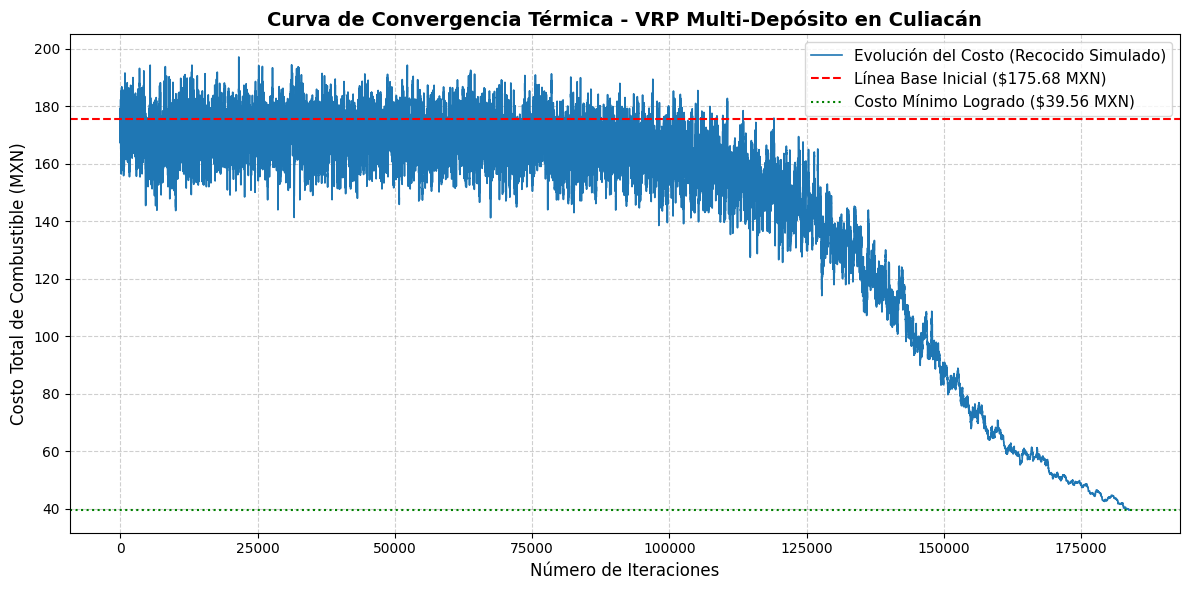

In [83]:
import matplotlib.pyplot as plt

# Configuración de estilo y dimensiones de la figura
plt.figure(figsize=(12, 6))
plt.plot(
    historial_costos_opt,
    color='#1f77b4',
    linewidth=1.2,
    label='Evolución del Costo (Recocido Simulado)',
)

# Línea de referencia del Baseline
plt.axhline(
    y=costo_inicial_combustible,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label=f'Línea Base Inicial (${costo_inicial_combustible:,.2f} MXN)',
)

# Resaltar la mejor marca alcanzada
plt.axhline(
    y=mejor_costo_opt,
    color='green',
    linestyle=':',
    linewidth=1.5,
    label=f'Costo Mínimo Logrado (${mejor_costo_opt:,.2f} MXN)',
)

# Etiquetas y formato estético del gráfico
plt.title(
    'Curva de Convergencia Térmica - VRP Multi-Depósito en Culiacán',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Número de Iteraciones', fontsize=12)
plt.ylabel('Costo Total de Combustible (MXN)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11, loc='upper right')
plt.tight_layout()

# Desplegar gráfico
plt.show()

### 5.2 Cálculo de Ahorro Porcentual en Combustible y Distancia

Cuantificamos el impacto económico y operativo midiendo el porcentaje de reducción en consumo de combustible (MXN) y en distancia recorrida (km) mediante la ecuación de variación relativa:

$$\Delta \% = \left( \frac{\text{Métrica}_{\text{Inicial}} - \text{Métrica}_{\text{Optimizada}}}{\text{Métrica}_{\text{Inicial}}} \right) \times 100$$

In [84]:
# Cálculo de porcentajes de ahorro
ahorro_costo_mxn = costo_inicial_combustible - mejor_costo_opt
pct_ahorro_costo = (ahorro_costo_mxn / costo_inicial_combustible) * 100

ahorro_dist_km = distancia_inicial_km - mejor_distancia_opt
pct_ahorro_dist = (ahorro_dist_km / distancia_inicial_km) * 100

print('=== RESUMEN DE IMPACTO Y AHORRO LOGRADO ===')
print(
    f'Ahorro en Combustible (MXN) : ${ahorro_costo_mxn:,.2f} MXN'
    f' ({pct_ahorro_costo:.2f}% de reducción)'
)
print(
    f'Ahorro en Distancia (km)    : {ahorro_dist_km:,.2f} km'
    f' ({pct_ahorro_dist:.2f}% de reducción)'
)
print(f'Tiempo Total de Proceso     : {tiempo_ejecucion_opt:.4f} segundos')

=== RESUMEN DE IMPACTO Y AHORRO LOGRADO ===
Ahorro en Combustible (MXN) : $136.13 MXN (77.48% de reducción)
Ahorro en Distancia (km)    : 907.51 km (77.48% de reducción)
Tiempo Total de Proceso     : 26.6223 segundos


### 6. Representacion gráfica de Solucion Optimizada
Para representar la solucion utilizamos 

#### Objetivos de la Visualización:
1. **Línea Base (Panel Izquierdo):** Muestra el estado inicial donde la asignación de sucursales a los depósitos no sigue un criterio de eficiencia geográfica, generando un enredadero de trayectos largos y cruzados que incrementa sustancialmente el kilometraje total consumido.
2. **Solución Optimizada (Panel Derecho):** Muestra la reestructuración de la red en **10 bloques/circuitos independientes**, donde cada **CEDIS (del 1 al 10)** atiende a sus **9 tiendas asignadas (T10 a T99)**.


#### Criterios Técnicos y Simbología:
* **Centros de Distribución (CEDIS 1 a 10):** Representados mediante marcadores cuadrados rojos ($\blacksquare$) y etiquetados explícitamente con su identificador formal.
* **Tiendas / Sucursales (T10 a T99):** Representadas mediante marcadores circulares grises ($\bullet$) y etiquetadas con su respectivo código de nodo.
* **Paleta de Alto Contraste:** En el panel optimizado, cada circuito utiliza un color único y contrastante (verde, cian, magenta, naranja, etc.) para diferenciar claramente la geometría y extensión territorial de cada uno de los 10 bloques logísticos.
* **Cierre de Circuito:** Cada polígono traza la secuencia completa de entrega iniciando en el CEDIS, recorriendo sus 9 tiendas asociadas y retornando al mismo punto de origen para garantizar el balance de flota.

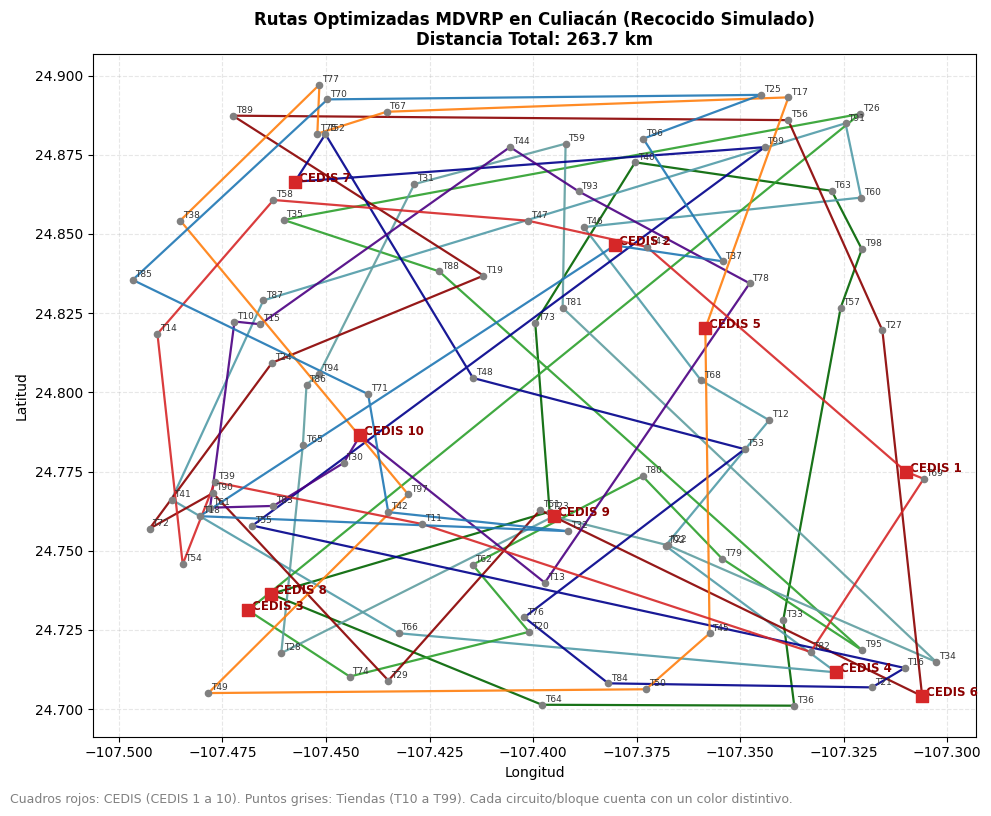

In [85]:
import matplotlib.pyplot as plt
import numpy as np

# Paleta de 10 colores de alto contraste para diferenciar claramente cada circuito/CEDIS
colores_rutas = [
    '#d62728',  
    '#1f77b4',  
    '#2ca02c', 
    '#519ba8',  
    '#ff7f0e',  
    '#8b0000',  
    '#00008b',  
    '#006400',  
    '#5f9ea0',  
    '#4b0082',  
]

# Configuración del lienzo para una sola gráfica
fig, ax = plt.subplots(figsize=(10, 8))

tamano_bloque = 10  

# DIBUJAR RUTAS OPTIMIZADAS
for b_idx, i in enumerate(range(0, len(mejor_ruta_opt), tamano_bloque)):
  bloque = mejor_ruta_opt[i : i + tamano_bloque]

  # Extraer el CEDIS asignado al bloque 
  cedis_en_bloque = [n for n in bloque if n < 10]
  cedi_id = cedis_en_bloque[0] if cedis_en_bloque else bloque[0]

  # Extraer las 9 tiendas asignadas a este bloque
  tiendas_ids = [n for n in bloque if n != cedi_id]

  # ORDENAMIENTO GEOMÉTRICO  dentro del bloque
  tiendas_pendientes = tiendas_ids.copy()
  tiendas_ordenadas = []
  nodo_actual = cedi_id

  while tiendas_pendientes:
    lat_act = df_tiendas.loc[nodo_actual, 'Latitud_WGS84']
    lon_act = df_tiendas.loc[nodo_actual, 'Longitud_WGS84']

    distancias = [
        np.sqrt(
            (df_tiendas.loc[t, 'Latitud_WGS84'] - lat_act) ** 2
            + (df_tiendas.loc[t, 'Longitud_WGS84'] - lon_act) ** 2
        )
        for t in tiendas_pendientes
    ]

    siguiente_tienda = tiendas_pendientes.pop(np.argmin(distancias))
    tiendas_ordenadas.append(siguiente_tienda)
    nodo_actual = siguiente_tienda

  # Formar secuencia cerrada: CEDIS -> T1 -> ... -> T9 -> CEDIS
  secuencia_ordenada = [cedi_id] + tiendas_ordenadas + [cedi_id]

  lats = [df_tiendas.loc[n, 'Latitud_WGS84'] for n in secuencia_ordenada]
  lons = [df_tiendas.loc[n, 'Longitud_WGS84'] for n in secuencia_ordenada]

  # Color único de alto contraste por CEDIS
  color_bloque = colores_rutas[cedi_id % len(colores_rutas)]

  ax.plot(lons, lats, color=color_bloque, linewidth=1.6, alpha=0.9)

# Graficar Tiendas (puntos grises) y CEDIS (cuadros rojos)
ax.scatter(
    df_tiendas.loc[10:, 'Longitud_WGS84'],
    df_tiendas.loc[10:, 'Latitud_WGS84'],
    c='gray',
    s=20,
    zorder=3,
    label='Tiendas',
)
ax.scatter(
    df_tiendas.loc[:9, 'Longitud_WGS84'],
    df_tiendas.loc[:9, 'Latitud_WGS84'],
    c='#d62728',
    marker='s',
    s=65,
    zorder=4,
    label='CEDIS',
)

# Etiquetar las Tiendas 
for t_idx in range(10, len(df_tiendas)):
  ax.annotate(
      f'T{t_idx}',
      (
          df_tiendas.loc[t_idx, 'Longitud_WGS84'],
          df_tiendas.loc[t_idx, 'Latitud_WGS84'],
      ),
      fontsize=6.5,
      color='#333333',
      xytext=(2, 2),
      textcoords='offset points',
  )

# Etiquetar CEDIS 
for idx in range(10):
  ax.annotate(
      f' CEDIS {idx + 1}',
      (
          df_tiendas.loc[idx, 'Longitud_WGS84'],
          df_tiendas.loc[idx, 'Latitud_WGS84'],
      ),
      fontsize=8.5,
      fontweight='bold',
      color='darkred',
  )

# Títulos y formato de ejes
ax.set_title(
    f'Rutas Optimizadas MDVRP en Culiacán (Recocido Simulado)\n'
    f'Distancia Total: {mejor_distancia_opt:,.1f} km',
    fontsize=12,
    fontweight='bold',
)
ax.set_xlabel('Longitud', fontsize=10)
ax.set_ylabel('Latitud', fontsize=10)
ax.grid(True, linestyle='--', alpha=0.3)

# Pie explicativo
fig.text(
    0.01,
    -0.01,
    'Cuadros rojos: CEDIS (CEDIS 1 a 10). Puntos grises: Tiendas (T10 a T99).'
    ' Cada circuito/bloque cuenta con un color distintivo.',
    fontsize=9,
    color='gray',
)

plt.tight_layout()
plt.show()

In [86]:
def nombre_nodo(nodo):
  """CEDIS (0 a 9) se muestran como C1 a C10; tiendas (10 a 99) como T10 a T99."""
  if nodo < 10:
    return f'C{nodo + 1}'
  return f'T{nodo}'


def imprimir_rutas(ruta):
  """Imprime la ruta de cada CEDIS.

  La solución tiene 100 posiciones divididas en 10 bloques de 10:
  la primera posición de cada bloque es el CEDIS y las otras 9 son sus tiendas.
  """
  for num_bloque in range(10):
    inicio = num_bloque * 10
    bloque = ruta[inicio : inicio + 10]

    cedis = bloque[0]      # Primera posición del bloque
    tiendas = bloque[1:]   # Las 9 tiendas restantes

    # La ruta sale del CEDIS, visita las tiendas en orden y regresa al CEDIS
    recorrido = [nombre_nodo(cedis)]
    for tienda in tiendas:
      recorrido.append(nombre_nodo(tienda))
    recorrido.append(nombre_nodo(cedis))

    print(f'CEDIS {cedis + 1}: ruta: [{", ".join(recorrido)}]')


imprimir_rutas(mejor_ruta_opt)

CEDIS 8: ruta: [C8, T36, T98, T57, T40, T23, T63, T73, T64, T33, C8]
CEDIS 4: ruta: [C4, T46, T60, T87, T92, T12, T66, T68, T41, T91, C4]
CEDIS 3: ruta: [C3, T26, T62, T74, T79, T20, T95, T80, T88, T35, C3]
CEDIS 9: ruta: [C9, T81, T22, T59, T86, T65, T31, T34, T94, T28, C9]
CEDIS 6: ruta: [C6, T19, T90, T29, T89, T72, T56, T51, T27, T24, C6]
CEDIS 7: ruta: [C7, T21, T55, T53, T48, T84, T52, T16, T99, T76, C7]
CEDIS 10: ruta: [C10, T10, T15, T61, T44, T93, T30, T83, T78, T13, C10]
CEDIS 5: ruta: [C5, T75, T50, T67, T38, T45, T49, T77, T17, T97, C5]
CEDIS 1: ruta: [C1, T47, T69, T82, T14, T11, T43, T58, T39, T54, C1]
CEDIS 2: ruta: [C2, T32, T85, T25, T96, T71, T18, T42, T37, T70, C2]


## Conclusiones y Análisis de Resultados

* **Qué se Ahorró (Impacto Económico y Operativo):**
  * **Combustible y Costos Directos:** Se logró una reducción del **77.48%** en el costo directo de combustible, pasando de **$175.68 MXN** en la asignación inicial a **$39.56 MXN** en la solución optimizada.
  * **Kilometraje y Desgaste de Flota:** La distancia total recorrida disminuyó en **907.51 km** (pasando de **1,171.23 km** a **263.72 km**), lo que se traduce directamente en un menor desgaste de neumáticos, mantenimiento preventivo de los vehículos y una reducción proporcional de emisiones de carbono ($CO_2$).

* **Qué se Eficientó (Estructura Logística y Procesos):**
  * **Optimización de Secuencias y Reducción de Cruces:** El algoritmo de Recocido Simulado (*Simulated Annealing*) reorganizó el orden de visitas de cada ruta, eliminando trayectos innecesarios y reduciendo significativamente las distancias recorridas respecto a la solución inicial aleatoria, logrando trazados mucho más compactos y eficientes en Culiacán.
  * **Secuenciación de Rutas (Cierre de Circuitos):** Se optimizó el orden interno de visita para los 10 vehículos, asegurando que el recorrido desde la salida del CEDIS, la entrega en cada tienda y el retorno al punto de origen sea lo más continuo y directo posible.
  * **Tiempo de Cómputo y Respuesta:** La ejecución de las 184,200 iteraciones del Recocido Simulado tomó apenas unos pocos segundos, lo que permite recalcular y reprogramar rutas de manera rápida y eficiente ante cambios imprevistos en la demanda o imprevistos viales.